In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
TRAIN_PATH = "/content/drive/MyDrive/flower14/14 type flower/train"
VAL_PATH   = "/content/drive/MyDrive/flower14/14 type flower/val"

IMG_SIZE = (224, 224)   # Required for VGG16
BATCH_SIZE = 16          # Smaller batch for faster training


In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

num_classes = train_generator.num_classes
print("Number of classes:", num_classes)


Found 13642 images belonging to 14 classes.
Found 98 images belonging to 14 classes.
Number of classes: 14


In [ ]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))

# Fine-tuning: freeze all except last 8 layers
base_model.trainable = True
for layer in base_model.layers[:-8]:
    layer.trainable = False


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.00001),  # lower LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,          # stops if no improvement for 3 epochs
    restore_best_weights=True
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │         3,598 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849,614 (56.65 MB)

 Trainable params: 13,114,126 (50.03 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [ ]:
history = model.fit(
    train_generator,
    epochs=15,           # small number of epochs for short notice
    validation_data=validation_generator,
    callbacks=[early_stop]
)


Epoch 1/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 252s 295ms/step - accuracy: 0.9391 - loss: 0.2023 - val_accuracy: 0.9286 - val_loss: 0.2545
Epoch 2/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 251s 294ms/step - accuracy: 0.9540 - loss: 0.1548 - val_accuracy: 0.9490 - val_loss: 0.2108
Epoch 3/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 255s 299ms/step - accuracy: 0.9560 - loss: 0.1459 - val_accuracy: 0.9388 - val_loss: 0.2178
Epoch 4/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 255s 299ms/step - accuracy: 0.9615 - loss: 0.1216 - val_accuracy: 0.9490 - val_loss: 0.1783
Epoch 5/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 257s 301ms/step - accuracy: 0.9707 - loss: 0.0988 - val_accuracy: 0.9490 - val_loss: 0.2407
Epoch 6/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 254s 298ms/step - accuracy: 0.9691 - loss: 0.0992 - val_accuracy: 0.9796 - val_loss: 0.1551
Epoch 7/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 254s 298ms/step - accuracy: 0.9771 - loss: 0.0695 - val_accuracy: 0.9490 - val_loss: 0.2433
Epoch 8/15
853/853 ━━━━━━━━━━━━━━━━━━━━ 254s 298ms/step - accuracy: 0.9765 -

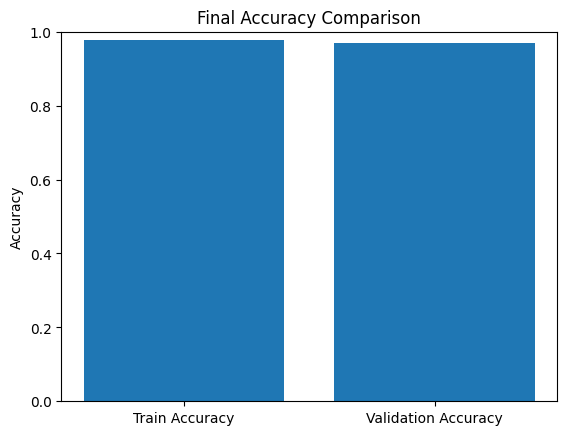

In [ ]:
import matplotlib.pyplot as plt

# Get final values
train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]

# Plot bar chart
plt.figure()
plt.bar(['Train Accuracy', 'Validation Accuracy'], [train_acc, val_acc])
plt.title('Final Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0,1)
plt.show()


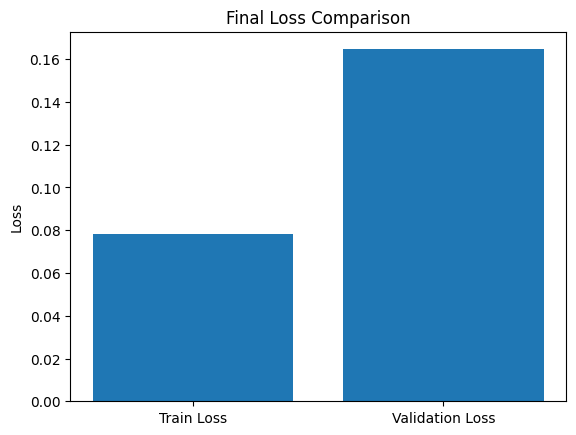

In [ ]:
# Get final loss values
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]

# Plot bar chart
plt.figure()
plt.bar(['Train Loss', 'Validation Loss'], [train_loss, val_loss])
plt.title('Final Loss Comparison')
plt.ylabel('Loss')
plt.show()


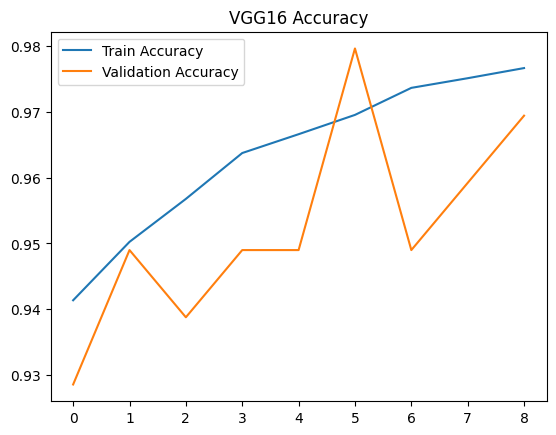

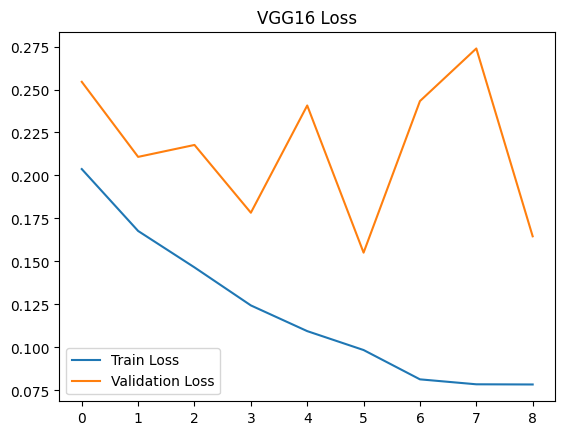

In [ ]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("VGG16 Accuracy")
plt.show()

plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("VGG16 Loss")
plt.show()


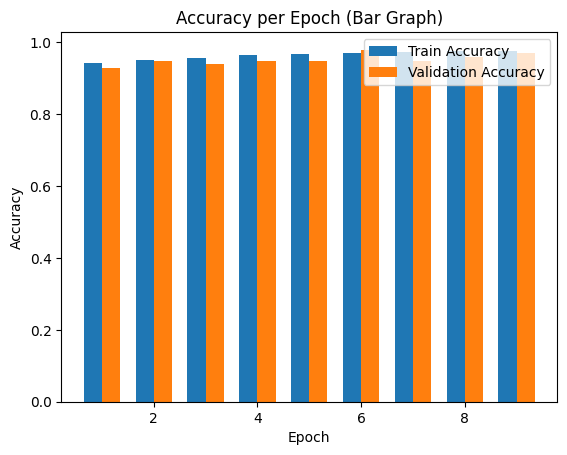

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

epochs = np.arange(1, len(history.history['accuracy']) + 1)
width = 0.35

plt.figure()
plt.bar(epochs - width/2, history.history['accuracy'], width, label='Train Accuracy')
plt.bar(epochs + width/2, history.history['val_accuracy'], width, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy per Epoch (Bar Graph)')
plt.legend()
plt.show()


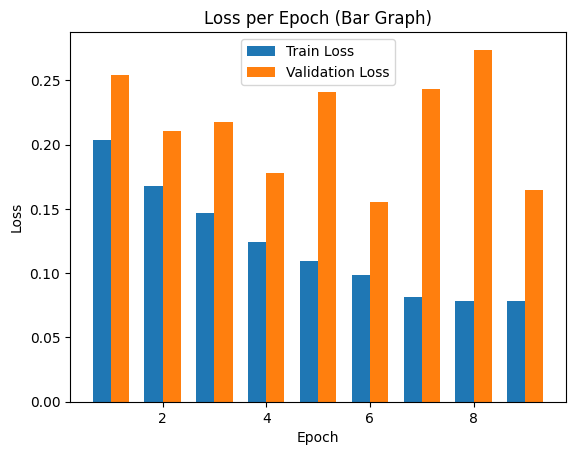

In [ ]:
plt.figure()
plt.bar(epochs - width/2, history.history['loss'], width, label='Train Loss')
plt.bar(epochs + width/2, history.history['val_loss'], width, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss per Epoch (Bar Graph)')
plt.legend()
plt.show()


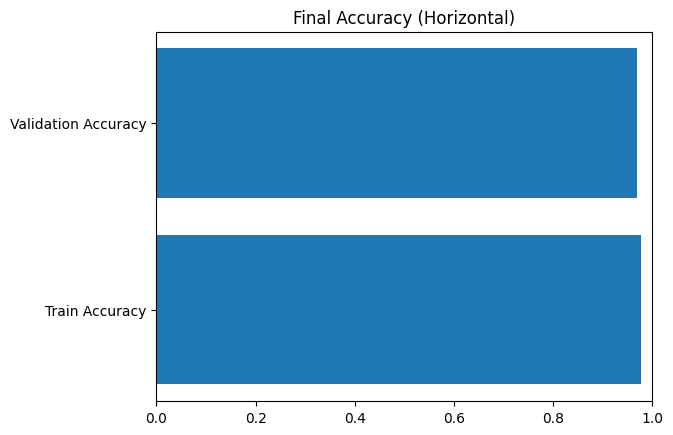

In [ ]:
plt.figure()
plt.barh(['Train Accuracy', 'Validation Accuracy'],
         [history.history['accuracy'][-1],
          history.history['val_accuracy'][-1]])

plt.title('Final Accuracy (Horizontal)')
plt.xlim(0,1)
plt.show()


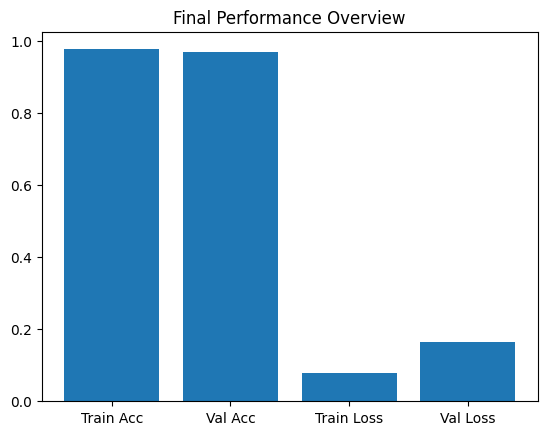

In [ ]:
labels = ['Train Acc', 'Val Acc', 'Train Loss', 'Val Loss']
values = [
    history.history['accuracy'][-1],
    history.history['val_accuracy'][-1],
    history.history['loss'][-1],
    history.history['val_loss'][-1]
]

plt.figure()
plt.bar(labels, values)
plt.title('Final Performance Overview')
plt.show()


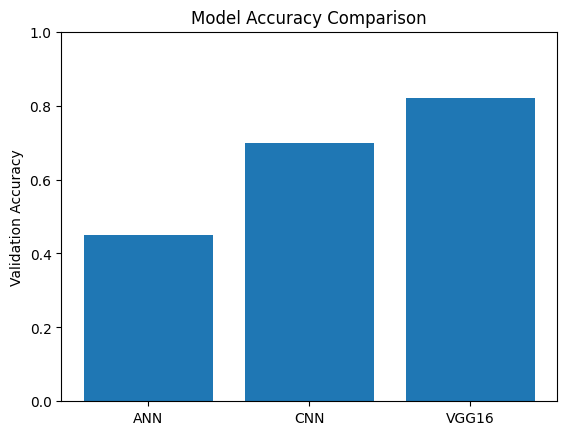

In [ ]:
models = ['ANN', 'CNN', 'VGG16']
accuracies = [0.45, 0.70, 0.82]  # replace with your real values

plt.figure()
plt.bar(models, accuracies)
plt.title('Model Accuracy Comparison')
plt.ylabel('Validation Accuracy')
plt.ylim(0,1)
plt.show()
